# Example 2: the ribbon model

The reduced ribbon model (`lib/ribbon_model.py`) on a pattern of concentric circles with the same overlap $D$ for every beam. Every cut contour is a rigid level that moves by a height $w$ and two small rotations; the $N$ beams between two contours are clamped into them. The model is linear and needs no simulation.

Run the notebook from the `examples/` folder. The script `02_ribbon_model.py` does the same.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore", category = RuntimeWarning)   # fsolve progress warnings of the section lines
import os, importlib
import numpy as np
from common import *   # also puts ../lib on the path
from ribbon_model import beams_from_pattern, RibbonModel, guided_stiffness
example2 = importlib.import_module('02_ribbon_model')   # for draw_sheet

RADIUS = 30.0     # outer contour, mm
WIDTH = 3.0       # ribbon width W, mm
OVERLAP = 2.0     # overlap D, mm
N = 6
YOUNG = 2100.0    # MPa
THICKNESS = 0.1   # mm
OFFSET = 5.0      # distance of the off-centre pull, mm
HEIGHT = 10.0     # pulled height, mm
out = output_dir('02_ribbon_model')

## Pattern and beams

The beams are read from the cutting pattern: each one runs between the facing tips of two overlapping cuts, so its length is $2D$.

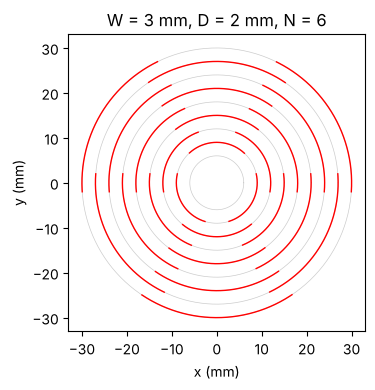

8 levels, 42 beams, beam length 4.03 mm


In [2]:
lines, spans, sheet = constant_overlap_sheet(RADIUS, WIDTH, overlap = OVERLAP, N = N)
plot_pattern(lines, spans, os.path.join(out, 'pattern.png'), 'W = %g mm, D = %g mm, N = %d' % (WIDTH, OVERLAP, N))
beams = beams_from_pattern(lines, spans, N, center = (0.0, 0.0))
model = RibbonModel(beams, young = YOUNG, thickness = THICKNESS)
print('%d levels, %d beams, beam length %.2f mm' % (model.n_levels, len(beams['L']), beams['L'].mean()))

## Central pull

The stiffness of a central pull is the paper's Eq. 1 summed over the levels: the levels act as springs in series, each made of $N$ guided beams in parallel.

In [3]:
k = model.stiffness((0.0, 0.0))
k_beam = guided_stiffness(beams['L'], beams['W'], YOUNG, THICKNESS, 0.4)
k_eq1 = 1/np.sum(1/np.bincount(beams['level'], k_beam))
print('central pull: %.4f N/mm (Eq. 1 summed over the levels: %.4f N/mm)' % (k, k_eq1))
q, force = model.pull_to((0.0, 0.0), HEIGHT)    # by displacement: the force is an unknown
print('at %g mm: force %.3f N, peak bending stress %.0f MPa' % (HEIGHT, force, model.max_stress(q).max()))

central pull: 0.0985 N/mm (Eq. 1 summed over the levels: 0.0985 N/mm)
at 10 mm: force 0.985 N, peak bending stress 67 MPa


## Off-centre pull

Pulled at $(x, 0)$, every level tilts towards the pulled side, more and more towards the top.

pull at x = 5 mm to 10 mm: 0.834 N, top level tilted 17.8 deg


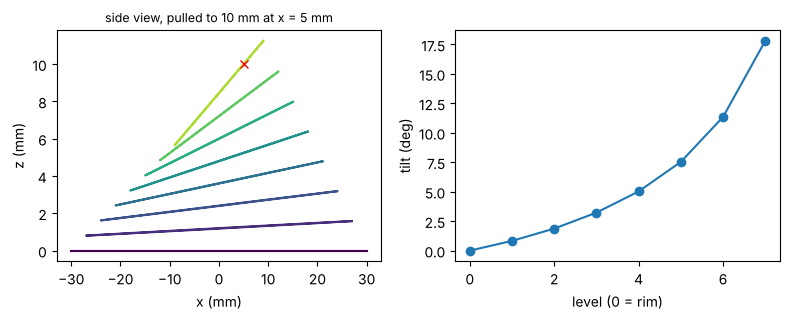

In [4]:
point = (OFFSET, 0.0)
q, force = model.pull_to(point, HEIGHT)
tilt = np.degrees(np.hypot(q[:, 1], q[:, 2]))
print('pull at x = %g mm to %g mm: %.3f N, top level tilted %.1f deg' % (OFFSET, HEIGHT, force, tilt[-1]))
fig, (a1, a2) = plt.subplots(1, 2, figsize = (8, 3.3))
for j, line in enumerate(model.deployed_lines(lines, q)):
    a1.plot(line[:, 0], line[:, 2], color = plt.cm.viridis(j/model.n_levels))
a1.plot(point[0], HEIGHT, 'rx')
a1.set_xlabel('x (mm)'); a1.set_ylabel('z (mm)')
a1.set_title('side view, pulled to %g mm at x = %g mm' % (HEIGHT, OFFSET), fontsize = 9)
a2.plot(np.arange(model.n_levels), tilt, 'o-')
a2.set_xlabel('level (0 = rim)'); a2.set_ylabel('tilt (deg)')
fig.tight_layout()
finish(fig, os.path.join(out, 'off_centre.png'))

## The deformed sheet

`classify` assigns every triangle to a panel of a level or to a beam, and `deform` moves the cut mesh: every panel follows the rigid motion of its level and every beam bends as the cubic between its clamped ends, with a linear twist. The kinematics are linear (x and y do not move), so the view is only faithful while the slopes stay small. Panels are in blue and beams in orange.

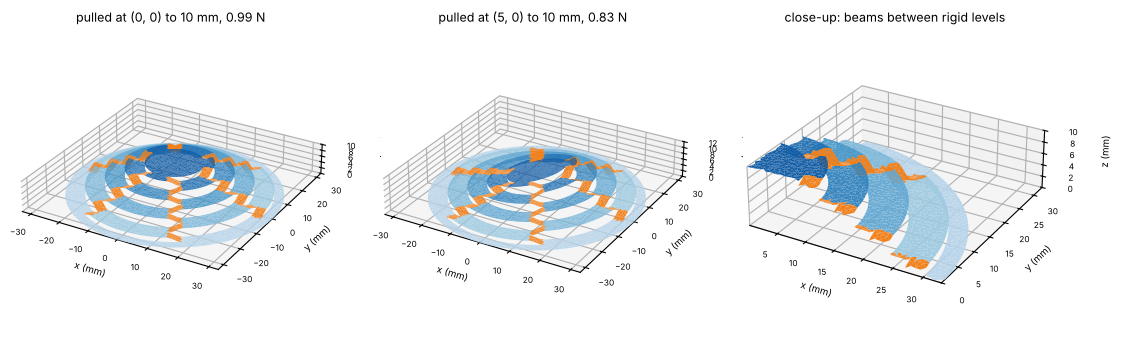

In [5]:
V, F = sheet['V'], sheet['F']
part, coord = model.classify(V, F, lines, spans)
fig = plt.figure(figsize = (11, 3.8))
for i, (name, point) in enumerate((('centre', (0.0, 0.0)), ('off_centre', (OFFSET, 0.0)))):
    q, force = model.pull_to(point, HEIGHT)
    X = model.deform(V, F, part, coord, q)
    igl.write_triangle_mesh(os.path.join(out, '%s_%02d.obj' % (name, round(HEIGHT))), X, F)
    example2.draw_sheet(fig.add_subplot(1, 3, i+1, projection = '3d'), X, F, part, model.n_levels,
                        'pulled at (%g, 0) to %g mm, %.2f N' % (point[0], HEIGHT, force))
q, force = model.pull_to((0.0, 0.0), HEIGHT)
r = np.abs(V[:, :2]).max()
example2.draw_sheet(fig.add_subplot(1, 3, 3, projection = '3d'), model.deform(V, F, part, coord, q), F, part, model.n_levels,
                    'close-up: beams between rigid levels', box = (0, r, 0, r))
fig.tight_layout()
finish(fig, os.path.join(out, 'deployment.png'))